# Finite-shot QAOA and VQE optimization

This notebook runs parameter search using **sampled objective estimates** on the same four-vertex MaxCut cycle and two-qubit Hamiltonian as the exact-statevector notebook. Independent ideal measurements are simulated by drawing counts from Qiskit statevector probabilities. Sampled outcomes and their estimated standard errors drive the decisions; exact expectations are used afterward for audit and display.

The sampling model includes no device noise or mitigation. The fixed search schedule and uncertainty margin are a reproducible heuristic, with no general convergence or approximation guarantee. We retain the full measured workload, including rejected proposals and fresh incumbent estimates.

Run this notebook in the pinned Python 3.12 environment. In a source checkout it loads that checkout's module explicitly. For a standalone run, save the **sampled** `optimization.py` download beside the notebook. Saved figures serve the site without a live kernel.

QAOA and VQE follow the original algorithm papers {cite:p}`opt_qaoa2014,opt_vqe2014`. Our circuits and measurement workflows are original. Qiskit core is Apache-2.0; NumPy is BSD-3-Clause; the implementation and notebook are MIT. The chapter bibliography records the exact upstream versions {cite:p}`opt_qiskit262,opt_numpy254,opt_matplotlib3112`.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import platform
import sys

# Select the actual worktree source, or one explicit standalone download.
# Do not silently resolve the original checkout's editable installation.
cwd = Path.cwd().resolve()
candidates = [
    ("checkout", cwd / "src/openquantum/optimization.py"),
    ("checkout", cwd.parent / "src/openquantum/optimization.py"),
    ("standalone sampled download", cwd / "optimization.py"),
    ("standalone sampled download", cwd / "notebooks/optimization.py"),
]
selected = next(((kind, path.resolve()) for kind, path in candidates if path.is_file()), None)
if selected is None:
    raise FileNotFoundError("Save sampled/optimization.py beside this notebook, or run from its checkout.")
source_kind, module_path = selected
spec = importlib.util.spec_from_file_location("optimization_sampled_notebook_source", module_path)
opt = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = opt
spec.loader.exec_module(opt)
assert Path(opt.__file__).resolve() == module_path
if not hasattr(opt, "run_sampled_demo"):
    raise ImportError("Use the sampled optimization.py download; the older exact-only module lacks this workflow.")
# Keep the actual path in the kernel; avoid publishing private absolute paths.
print({"source": source_kind,
       "implementation_sha256": hashlib.sha256(module_path.read_bytes()).hexdigest(),
       "python": platform.python_version(),
       "packages": {name: importlib.metadata.version(name) for name in ("qiskit", "numpy", "matplotlib")}})

import math
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector


{'source': 'checkout', 'implementation_sha256': 'a617b5e8d43b648427e5ceaa5e35d3f50ea14c02464465084f23f457ffb5855d', 'python': '3.12.14', 'packages': {'qiskit': '2.6.2', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}}


## Tasks and independent references

The unweighted cycle has edges $(0,1),(1,2),(2,3),(0,3)$. We maximize $C(z)=\sum_{(u,v)}[z_u\ne z_v]$, while the search minimizes the sampled negative cut mean. One all-Z measurement scores all edges jointly. QAOA prepares $|+\rangle^{\otimes4}$ with H on every qubit, uses CX–RZ$(−\gamma)$–CX for each edge, and RX$(2\beta)$ for the mixer. Angles are radians with $R_P(\alpha)=e^{-i\alpha P/2}$.

VQE minimizes the sampled energy of $H=-Z_0-Z_1+\tfrac12X_0X_1$ starting from $|00\rangle$, with $R_Y(\theta)$ on qubit 0 followed by CX$(0,1)$. The Hamiltonian coefficients and energies are dimensionless. A joint all-Z group measures $-Z_0-Z_1$; a separate all-X group measures $\tfrac12X_0X_1$. The all-X circuit applies H on both qubits before computational-basis readout. Combining measured Z terms before computing their variance retains their covariance.

The references below are for post-run checks. Neither classical answer is a parameter-search oracle.


In [2]:
edges = ((0, 1), (1, 2), (2, 3), (0, 3))
cut_values = np.array([sum(((z >> u) & 1) != ((z >> v) & 1) for u, v in edges)
                       for z in range(16)], dtype=float)
np.testing.assert_array_equal(cut_values, opt.maxcut_values(4, edges))
I = np.eye(2)
X = np.array([[0., 1.], [1., 0.]])
Z = np.diag([1., -1.])
reference_hamiltonian = -np.kron(I, Z) - np.kron(Z, I) + .5*np.kron(X, X)
np.testing.assert_allclose(reference_hamiltonian, opt.vqe_hamiltonian(), rtol=0, atol=1e-14)
reference_energy = float(np.linalg.eigvalsh(reference_hamiltonian)[0])
np.testing.assert_allclose(reference_energy, -np.sqrt(4.25), rtol=0, atol=1e-14)
print({"classical_maximum_cut": float(cut_values.max()),
       "optimal_bitstrings": [f"{z:04b}" for z in np.flatnonzero(cut_values == 4)],
       "exact_ground_energy": reference_energy})


{'classical_maximum_cut': 4.0, 'optimal_bitstrings': ['0101', '1010'], 'exact_ground_energy': -2.0615528128088303}


## Fixed sampled search and fresh validation

For each run, the initial objective uses 256 shots per measurement group. The search has 32 sweeps in four consecutive eight-sweep blocks:

| Sweeps | Coordinate step (radians) | Shots per objective group |
|---|---:|---:|
| 1–8 | 0.4 | 256 |
| 9–16 | 0.2 | 512 |
| 17–24 | 0.1 | 1,024 |
| 25–32 | 0.05 | 2,048 |

Every sweep freshly estimates the incumbent and each negative and positive coordinate proposal. The lowest sampled proposal is accepted only when its apparent decrease exceeds twice the combined estimated standard error. This is a selection heuristic, not a calibrated confidence test across the search. A finite number of shots can misrank candidates.

The schedule always ends after 32 sweeps, then estimates the final state with a fresh 4,096 shots per group. Validation uses a separate random-stream family and is excluded from training decisions. The PCG64 stream uses `SeedSequence([seed, algorithm_id], spawn_key=(family, call_index, group_index))`, separating the algorithms, training/validation family, calls and measurement bases. The three seeds `7`, `19`, `41` are paired with QAOA initial points `(0.2,0.1)`, `(0.6,0.4)`, `(-0.3,0.25)` and VQE angles `0.6`, `-1.1`, `2.2`. These cases jointly vary seed and initialization; they do not isolate either effect.


In [3]:
# This runs measured objectives and all 32 sweeps for each predeclared case.
# The implementation adds exact diagnostics only after each search has finished.
sampled = opt.run_sampled_demo()
assert sampled["exact_diagnostics_used_for_optimization"] is False
assert sampled["physical_resource_estimate"] is None
print({"completed_seed_start_cases": sum(len(sampled[a]["runs"]) for a in ("qaoa", "vqe")),
       "training_modeled_shots": sampled["training_shots"],
       "independent_validation_modeled_shots": sampled["validation_shots"],
       "total_modeled_shots": sampled["total_shots"],
       "workflow_CPU_wall_seconds": sampled["workflow_wall_seconds"]})


{'completed_seed_start_cases': 6, 'training_modeled_shots': 1016064, 'independent_validation_modeled_shots': 36864, 'total_modeled_shots': 1052928, 'workflow_CPU_wall_seconds': 1.4051859950000107}


## Reconstruct the decisions from measured data

The following check reconstructs every observed mean and sample variance from its measured counts. It then replays the parameter decisions using **only** measured estimates, standard errors and the prescribed margin. Exact audit fields are excluded from this replay.

All rejected proposals remain in the record and count toward the workload. Re-estimating the incumbent means the displayed sampled trajectory need not be monotone, even when accepted parameter updates appear favorable. The main chapter's native MyST table is generated independently by the sampled artifact script; this notebook reports its own fresh execution.


In [4]:
def outcome_score(algorithm, group, bits):
    z = int(bits, 2)
    if algorithm == "qaoa":
        return float(sum(((z >> u) & 1) != ((z >> v) & 1) for u, v in edges))
    if group["group"] == "all_z":
        return -(1 - 2*((z >> 0) & 1)) - (1 - 2*((z >> 1) & 1))
    return .5*(1 - 2*((z >> 0) & 1))*(1 - 2*((z >> 1) & 1))


for algorithm in ("qaoa", "vqe"):
    dimension = 2 if algorithm == "qaoa" else 1
    expected_training_calls = 1 + 32*(1 + 2*dimension)
    expected_training_shots = (1 if algorithm == "qaoa" else 2)*(256 + (1 + 2*dimension)*8*(256 + 512 + 1024 + 2048))
    for run in sampled[algorithm]["runs"]:
        assert run["objective_evaluations"] == expected_training_calls
        assert run["iteration_count"] == 32
        assert run["stop_reason"] == "fixed_schedule_exhausted"
        assert run["total_shots"] == expected_training_shots
        calls = run["evaluations"]
        for call in calls + [run["validation"]]:
            means, mean_variances = [], []
            for group in call["groups"]:
                assert sum(group["counts"].values()) == group["shots"]
                mean = sum(count*outcome_score(algorithm, group, bits)
                           for bits, count in group["counts"].items()) / group["shots"]
                variance = sum(count*(outcome_score(algorithm, group, bits) - mean)**2
                               for bits, count in group["counts"].items()) / (group["shots"] - 1)
                np.testing.assert_allclose(mean, group["estimate"], rtol=0, atol=1e-12)
                np.testing.assert_allclose(variance, group["sample_variance"], rtol=1e-12, atol=1e-12)
                means.append(mean)
                mean_variances.append(variance/group["shots"])
            signed_mean = -sum(means) if algorithm == "qaoa" else sum(means)
            np.testing.assert_allclose(signed_mean, call["objective_estimate"], rtol=0, atol=1e-12)
            np.testing.assert_allclose(np.sqrt(sum(mean_variances)), call["estimated_standard_error"], rtol=1e-12, atol=1e-12)
        point = (np.array(run["initial"]) + np.pi) % (2*np.pi) - np.pi
        for iteration in run["iterations"]:
            incumbent = calls[iteration["incumbent_evaluation"]]
            proposals = [calls[index] for index in iteration["proposal_evaluations"]]
            np.testing.assert_allclose(incumbent["parameters"], point, rtol=0, atol=1e-12)
            best = min(proposals, key=lambda item: item["objective_estimate"])
            margin = 2*np.hypot(incumbent["estimated_standard_error"], best["estimated_standard_error"])
            accepted = incumbent["objective_estimate"] - best["objective_estimate"] > margin
            assert accepted == iteration["accepted"]
            assert best["index"] == iteration["best_proposal_evaluation"]
            if accepted:
                point = np.array(best["parameters"])
            np.testing.assert_allclose(iteration["parameters_after"], point, rtol=0, atol=1e-12)
        np.testing.assert_allclose(run["parameters"], point, rtol=0, atol=1e-12)
        assert all(group["rng"]["spawn_key"][0] == 0 for call in calls for group in call["groups"])
        assert all(group["rng"]["spawn_key"][0] == 1 for group in run["validation"]["groups"])
print("Reconstructed all 780 training/validation objective calls from counts and replayed all 192 sampled sweeps.")


Reconstructed all 780 training/validation objective calls from counts and replayed all 192 sampled sweeps.


## Sampled trajectories and post-decision exact audits

Solid lines show sampled estimates at the chosen states after each sweep: the accepted proposal estimate after an update, or the fresh incumbent estimate otherwise. Dashed lines show the exact expectation of those same parameters, computed after training. The exact curves do not drive the search. Colors identify the three predeclared seed and initialization pairs.

Expected cut is plotted with a positive sign, reversing the negative objective minimized by QAOA. VQE is plotted with the energy sign used by the optimizer. The reference lines are the depth-one cycle's analytic expected-cut maximum and the Hamiltonian's exact ground energy.


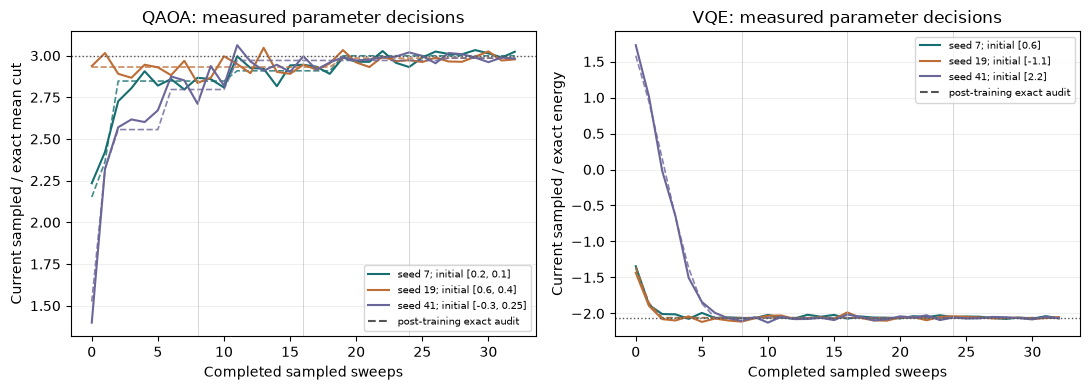

In [5]:
from matplotlib.lines import Line2D
colors = ("#176e70", "#bd6d36", "#6a6699")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, algorithm in zip(axes, ("qaoa", "vqe")):
    sign = -1 if algorithm == "qaoa" else 1
    handles = []
    for color, run in zip(colors, sampled[algorithm]["runs"]):
        calls = run["evaluations"]
        selected_calls = [calls[0]] + [calls[it["best_proposal_evaluation"] if it["accepted"] else it["incumbent_evaluation"]]
                                        for it in run["iterations"]]
        observed = [sign*call["objective_estimate"] for call in selected_calls]
        audit = [sign*calls[0]["exact_objective_audit"]] + [sign*it["exact_objective_after_audit"]
                                                                       for it in run["iterations"]]
        line, = ax.plot(range(33), observed, color=color, lw=1.5, label=f"seed {run['seed']}; initial {run['initial']}")
        ax.plot(range(33), audit, color=color, lw=1.2, ls="--", alpha=.8)
        handles.append(line)
    target = 3 if algorithm == "qaoa" else reference_energy
    ax.axhline(target, color="#555555", lw=1, ls=":")
    ax.set(xlabel="Completed sampled sweeps", ylabel="Current sampled / exact mean cut" if algorithm == "qaoa" else "Current sampled / exact energy",
           title="QAOA: measured parameter decisions" if algorithm == "qaoa" else "VQE: measured parameter decisions")
    for boundary in (8, 16, 24):
        ax.axvline(boundary, color="#bbbbbb", lw=.6, alpha=.7)
    handles.append(Line2D([0], [0], color="#555555", ls="--", label="post-training exact audit"))
    ax.legend(handles=handles, fontsize=7.5, loc="best")
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
from IPython.display import display
display(fig)
plt.close(fig)


## Independent final readout

The final validation counts come from a separate random-stream family at the selected parameters. Markers show the validation sample means with **one estimated standard error**; these error bars are descriptive, not rigorous confidence intervals. Hollow markers show exact post-training expectations. The separate Hoeffding radii printed below give 95% bounds for each independently validated fixed mean, conditional on the trained parameters. They do not cover the adaptive training path simultaneously.

For QAOA, one group uses 4,096 shots. VQE uses 4,096 shots in each of two groups, totaling 8,192 state preparations. A sampled energy can lie below the ground energy through statistical fluctuation.


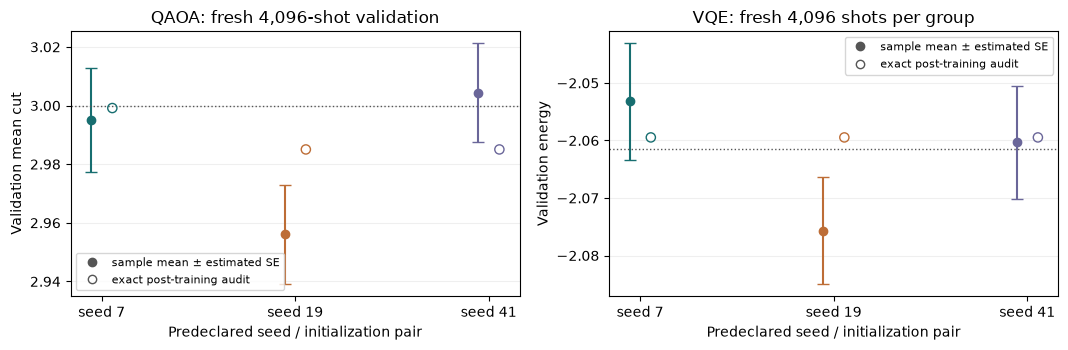

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.6))
for ax, algorithm in zip(axes, ("qaoa", "vqe")):
    sign = -1 if algorithm == "qaoa" else 1
    runs = sampled[algorithm]["runs"]
    for position, (color, run) in enumerate(zip(colors, runs)):
        validation = run["validation"]
        ax.errorbar(position-.055, sign*validation["objective_estimate"],
                    yerr=validation["estimated_standard_error"], color=color, fmt="o", capsize=4)
        ax.scatter(position+.055, sign*validation["exact_objective_audit"],
                   facecolors="none", edgecolors=color, s=44, zorder=3)
    ax.axhline(3 if algorithm == "qaoa" else reference_energy, color="#555555", ls=":", lw=1)
    ax.set(xticks=range(3), xticklabels=[f"seed {run['seed']}" for run in runs],
           xlabel="Predeclared seed / initialization pair", ylabel="Validation mean cut" if algorithm == "qaoa" else "Validation energy",
           title="QAOA: fresh 4,096-shot validation" if algorithm == "qaoa" else "VQE: fresh 4,096 shots per group")
    ax.legend(handles=[Line2D([0], [0], marker="o", color="#555555", linestyle="none", label="sample mean ± estimated SE"),
                       Line2D([0], [0], marker="o", markerfacecolor="none", color="#555555", linestyle="none", label="exact post-training audit")], fontsize=8)
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
display(fig)
plt.close(fig)


In [7]:
for algorithm in ("qaoa", "vqe"):
    print(algorithm.upper())
    sign = -1 if algorithm == "qaoa" else 1
    for run in sampled[algorithm]["runs"]:
        validation = run["validation"]
        print({"seed": run["seed"], "initial": run["initial"], "final_parameters_radians": run["parameters"],
               "training_objective_calls": run["objective_evaluations"], "independent_validation_calls": 1,
               "training_modeled_shots": run["total_shots"], "validation_modeled_shots": validation["total_shots"],
               "accepted_proposals": run["accepted_proposals"], "rejected_proposals": run["rejected_proposals"],
               "validation_mean": sign*validation["objective_estimate"],
               "exact_post_training_mean": sign*validation["exact_objective_audit"],
               "validation_95_Hoeffding_radius": validation["hoeffding_95_absolute_mean_radius"],
               "post_run_target_met": run["target_met_audit"]})


QAOA
{'seed': 7, 'initial': [0.2, 0.1], 'final_parameters_radians': [0.7999999999999998, 0.3999999999999999], 'training_objective_calls': 161, 'independent_validation_calls': 1, 'training_modeled_shots': 153856, 'validation_modeled_shots': 4096, 'accepted_proposals': 4, 'rejected_proposals': 124, 'validation_mean': 2.9951171875, 'exact_post_training_mean': 2.9991473878973767, 'validation_95_Hoeffding_radius': 0.08488134473378872, 'post_run_target_met': True}
{'seed': 19, 'initial': [0.6, 0.4], 'final_parameters_radians': [0.7000000000000002, 0.3999999999999999], 'training_objective_calls': 161, 'independent_validation_calls': 1, 'training_modeled_shots': 153856, 'validation_modeled_shots': 4096, 'accepted_proposals': 1, 'rejected_proposals': 127, 'validation_mean': 2.9560546875, 'exact_post_training_mean': 2.9850295372208437, 'validation_95_Hoeffding_radius': 0.08488134473378872, 'post_run_target_met': True}
{'seed': 41, 'initial': [-0.3, 0.25], 'final_parameters_radians': [-0.69999999

## Whole-workload logical accounting

Each measured group corresponds to fresh zero-state preparation, the actual ansatz and basis changes, and all final qubit measurements. The following ledger includes every initial call, incumbent refresh, proposal and validation group. Its shot-weighted circuit operations model ideal repetitions; they are not measured hardware consumption.

Classical simulation and control times are CPU timings. Physical reset latency, device routing, arbitrary-rotation synthesis and error correction remain excluded. A whole-trajectory physical estimate is pending: a single final circuit export or a fixed-readout projection cannot describe the full optimizer workload.


In [8]:
ledger = opt.sampled_run_resources(sampled)
assert ledger["total_shots"] == 1_052_928
for algorithm in ("qaoa", "vqe"):
    resources = ledger["algorithms"][algorithm]
    expected_shots = (157_952 if algorithm == "qaoa" else 193_024)*3
    assert resources["total_modeled_circuit_shots"] == expected_shots
    assert resources["total_modeled_qubit_readouts"] == expected_shots*(4 if algorithm == "qaoa" else 2)
    assert resources["shot_weighted_gate_counts"]["measure"] == resources["total_modeled_qubit_readouts"]
    for run in sampled[algorithm]["runs"]:
        final = run["parameters"]
        if algorithm == "qaoa":
            state = Statevector.from_instruction(opt.build_qaoa_circuit(4, edges, [final[0]], [final[1]]))
            dense_mean = float(state.probabilities() @ cut_values)
            scalar_mean = 2 + math.sin(4*final[1])*math.sin(2*final[0])
            np.testing.assert_allclose(dense_mean, scalar_mean, rtol=0, atol=1e-10)
            np.testing.assert_allclose(dense_mean, run["exact_expected_cut_audit"], rtol=0, atol=1e-10)
        else:
            state = Statevector.from_instruction(opt.build_vqe_circuit(final[0])).data
            dense_mean = float(np.vdot(state, reference_hamiltonian @ state).real)
            scalar_mean = -2*math.cos(final[0]) + .5*math.sin(final[0])
            np.testing.assert_allclose(dense_mean, scalar_mean, rtol=0, atol=1e-10)
            np.testing.assert_allclose(dense_mean, run["exact_energy_audit"], rtol=0, atol=1e-10)
    print({"algorithm": algorithm, "training_objective_calls": resources["objective_calls"],
           "independent_validation_calls": resources["independent_validation_calls"],
           "modeled_group_batches": resources["measured_group_batches"],
           "total_modeled_preparations": resources["total_modeled_circuit_shots"],
           "total_modeled_qubit_readouts": resources["total_modeled_qubit_readouts"],
           "shot_weighted_primitive_gates": resources["shot_weighted_gate_counts"],
           "physical_resource_estimate": ledger["physical_resource_estimate"]})
print("Independent final-state checks and whole sampled workload accounting passed.")


{'algorithm': 'qaoa', 'training_objective_calls': 483, 'independent_validation_calls': 3, 'modeled_group_batches': 486, 'total_modeled_preparations': 473856, 'total_modeled_qubit_readouts': 1895424, 'shot_weighted_primitive_gates': {'cx': 3790848, 'h': 1895424, 'rz': 1895424, 'rx': 1895424, 'measure': 1895424}, 'physical_resource_estimate': None}
{'algorithm': 'vqe', 'training_objective_calls': 291, 'independent_validation_calls': 3, 'modeled_group_batches': 588, 'total_modeled_preparations': 579072, 'total_modeled_qubit_readouts': 1158144, 'shot_weighted_primitive_gates': {'measure': 1158144, 'ry': 579072, 'cx': 579072, 'h': 579072}, 'physical_resource_estimate': None}
Independent final-state checks and whole sampled workload accounting passed.
